In [1]:
#Importando as bibliotecas necessárias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


# Sobre o Projeto

Este projeto implementa um modelo de **Aprendizado de Máquina Supervisionado** voltado para a **Classificação Binária** do diagnóstico de tumores de mama (**Maligno** vs. **Benigno**), a partir das características numéricas extraídas dos exames presentes no `data.csv`.

Como a variável que queremos prever (`diagnosis`) é uma **categoria**, e não um valor numérico contínuo, o problema se enquadra como **Classificação**, e não Regressão — é essa escolha que guia todo o restante do pipeline, como mostra o diagrama abaixo.

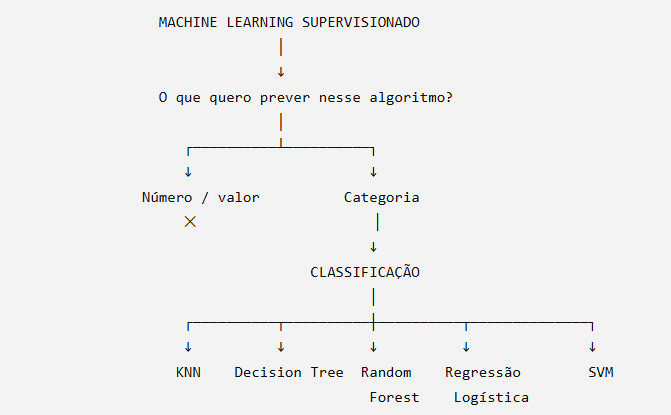

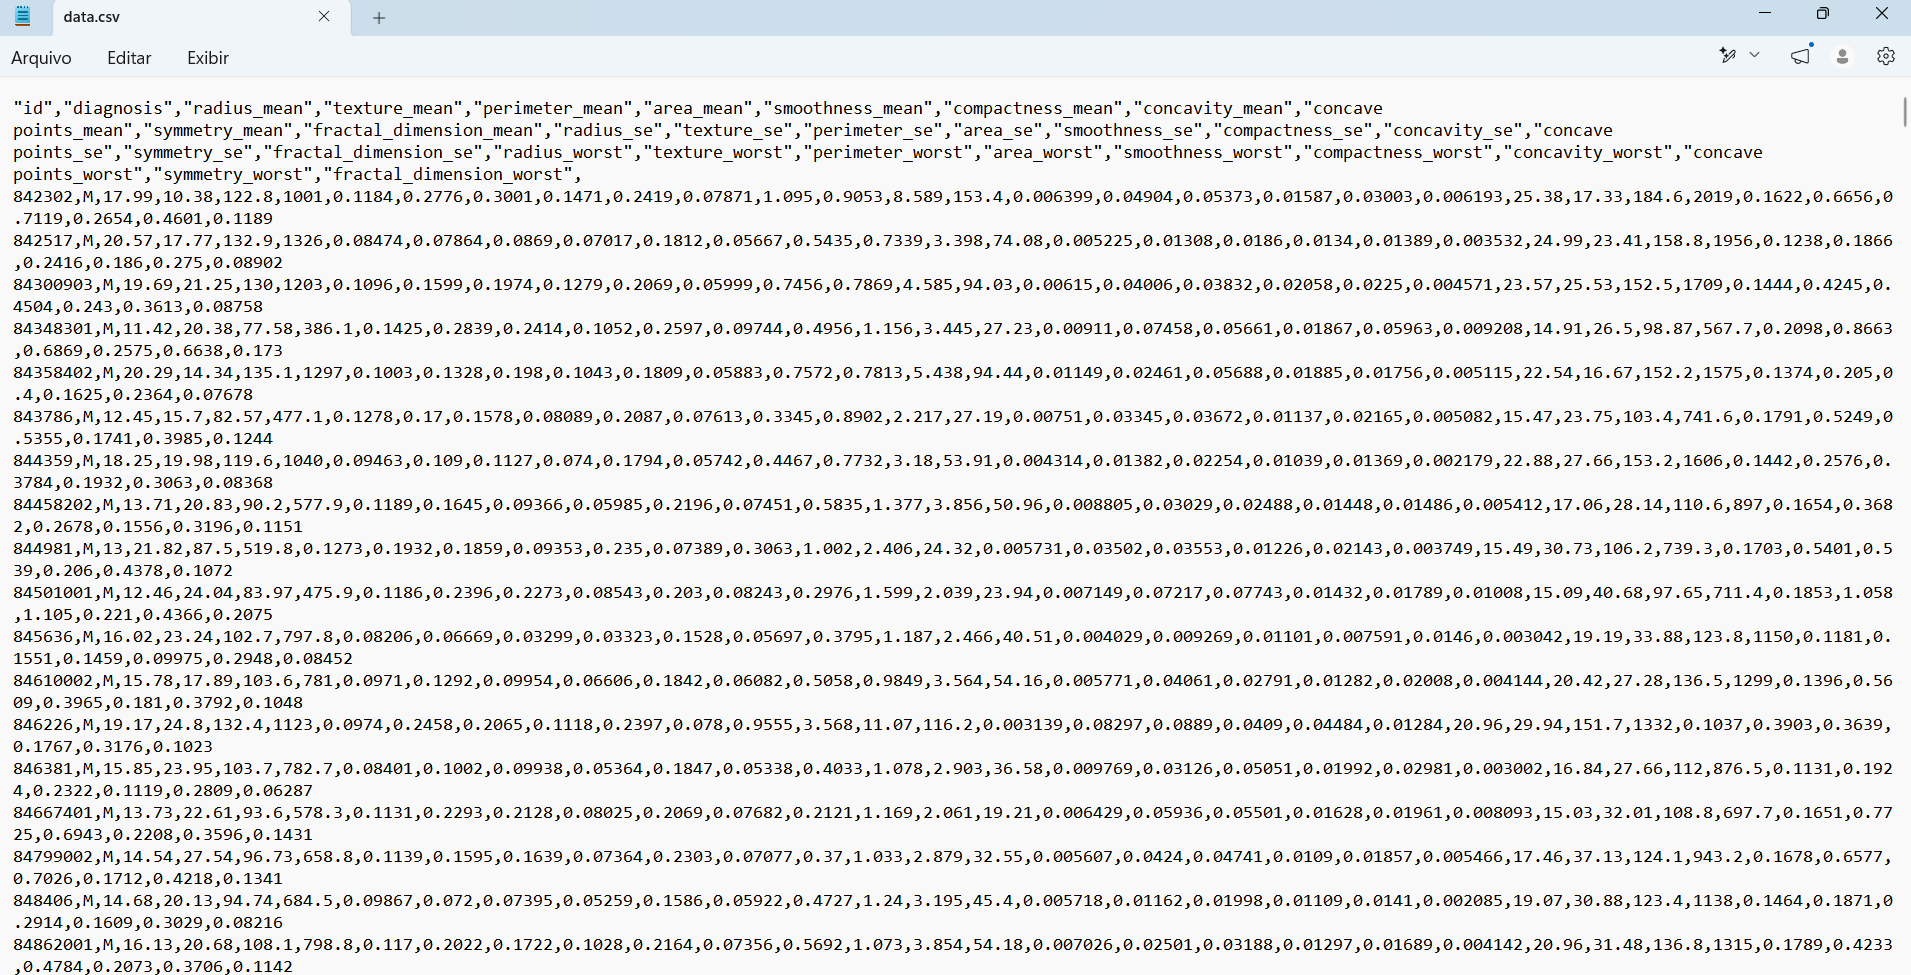

  #          Analisando o documento **data.csv** baixado


Analisando a imagem do nosso **bloco de notas** nosso dataset `data.csv` já está separado por **vírgulas**, que é o padrão do `pd.read_csv()`.
Por isso, podemos usar diretamente `pd.read_csv("data.csv")`, sem precisar informar `sep=";"` ou outro comando quando nossos dados estão separado por `;` ou outros caracter

In [2]:
# Importando a base de dados

dados = pd.read_csv("data.csv")

#Analisando a minha Tabela

In [3]:
# Verificando as primeiras linhas do DataFrame

dados.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
set(dados.diagnosis)

{'B', 'M'}

Não conseguimos analisar/ver todas as colunas na nossa tabela, então vamos utilizar a função `pd.set_option("display.max_columns", None)` para enxergarmos todas as colunas. Depois, analisaremos quantas colunas e linhas existem na tabela pelo atributo `dados.shape`, informações sobre valores nulos com `dados.isnull().sum()` e demais informações sobre nossa tabela.

In [5]:
pd.set_option("display.max_columns", None)
dados.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [6]:
# Verificando as dimensões do nosso arquivos

dados.shape

(569, 33)

In [7]:
#Verificando informações do meu arquivo

dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [8]:
#Verificando se há valores nulos

dados.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [9]:
dados.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


#Removendo colunas
Removendo colunas que não agregam valor à análise: `id` é apenas um identificador sem relação com o diagnóstico, e `Unnamed: 32` é uma coluna vazia, criada por uma vírgula extra no arquivo original.

In [10]:
dados = dados.drop(columns=['id', 'Unnamed: 32'])

In [11]:
dados.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Meus dados precisam de padronização?

Antes de avançar para a modelagem, é importante verificar se as variáveis apresentam *outliers* e se estão em escalas muito diferentes entre si. Vamos visualizar a distribuição das variáveis para responder essa pergunta — a justificativa completa será comentada logo após separarmos as *features* e o rótulo.

<Axes: >

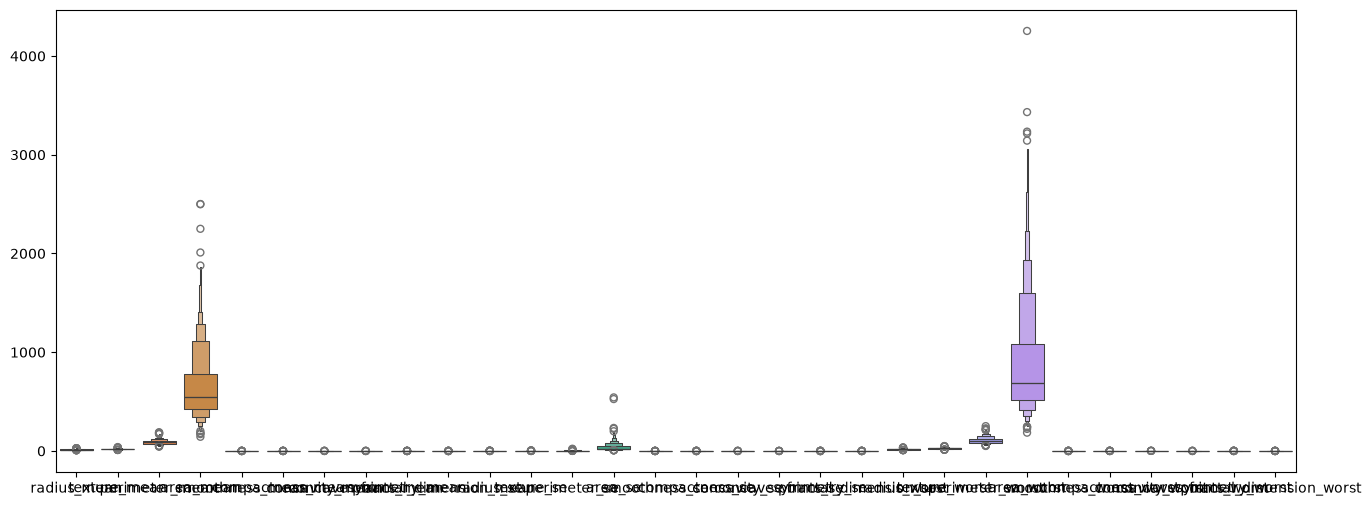

In [12]:
# Definir o tamanho da figura
plt.figure(figsize=(16,6))

# Gerar o gráfico
sns.boxenplot(data = dados)

<Axes: >

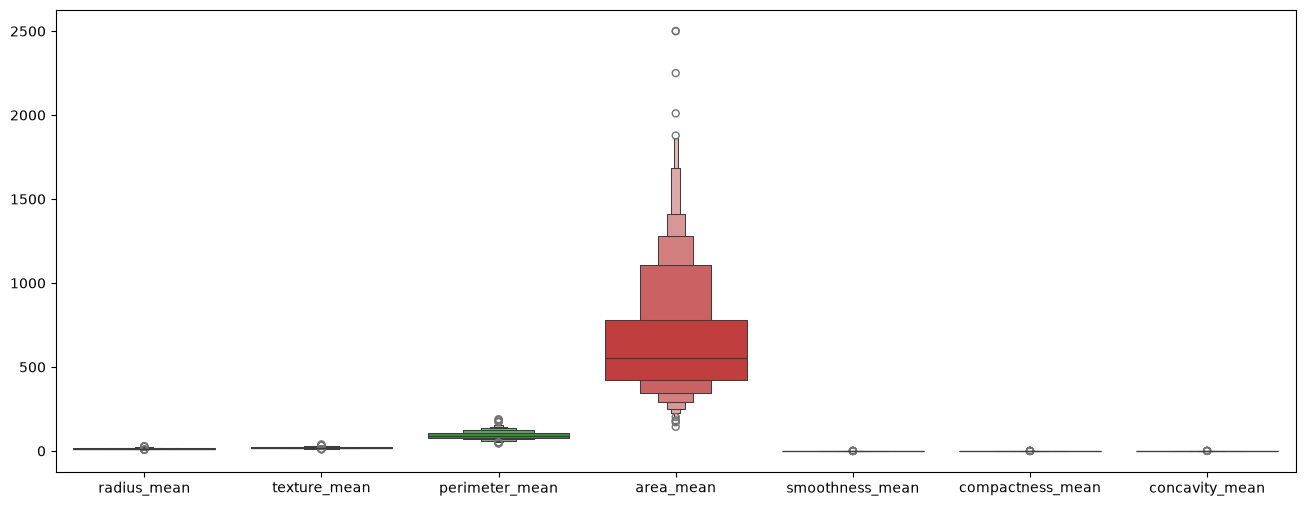

In [13]:
# Definir o tamanho da figura
plt.figure(figsize=(16, 6))

# Gerar o gráfico diretamente
sns.boxenplot(data=dados.iloc[:, :8]) # Exemplo com as 8 primeiras colunas

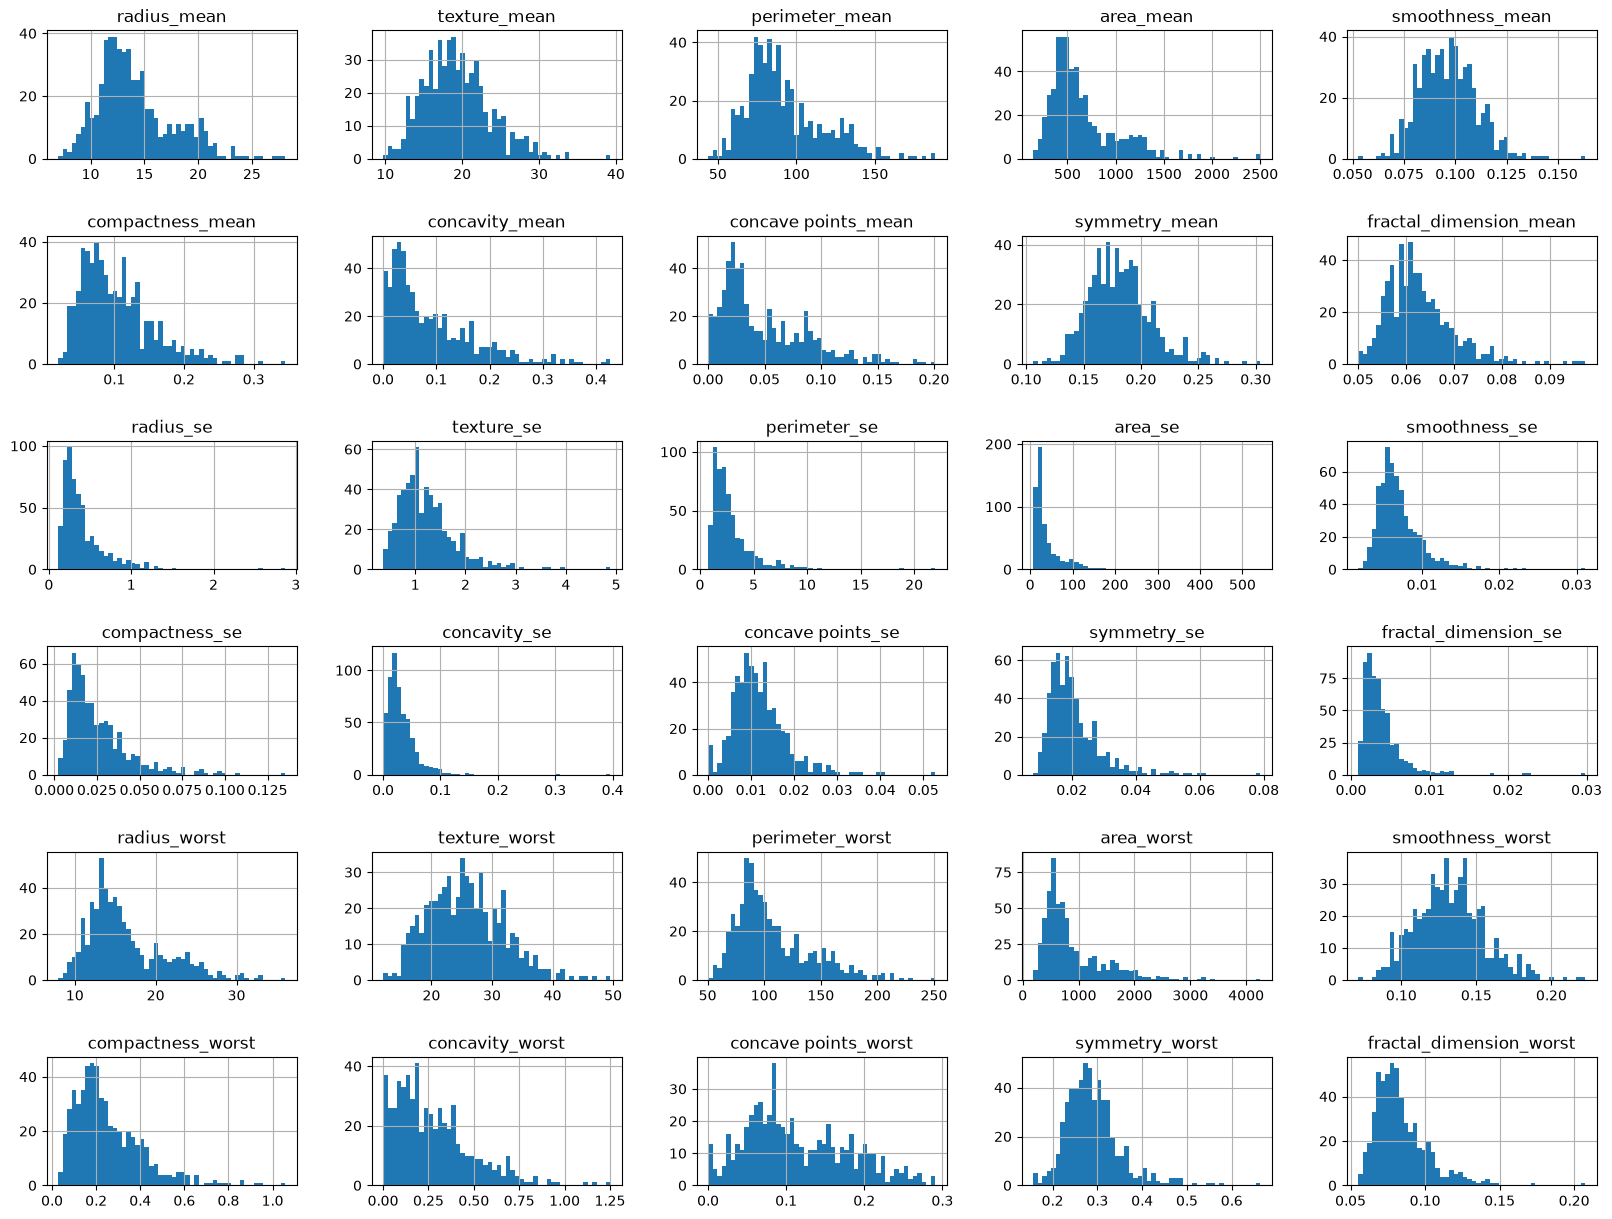

In [14]:
# Gera os histogramas
dados.hist(bins=50, figsize=(20,15))

# Aumenta o espaçamento vertical (hspace) e horizontal (wspace) entre subgráficos para uma melhor visualização
plt.subplots_adjust(hspace=0.6, wspace=0.3)

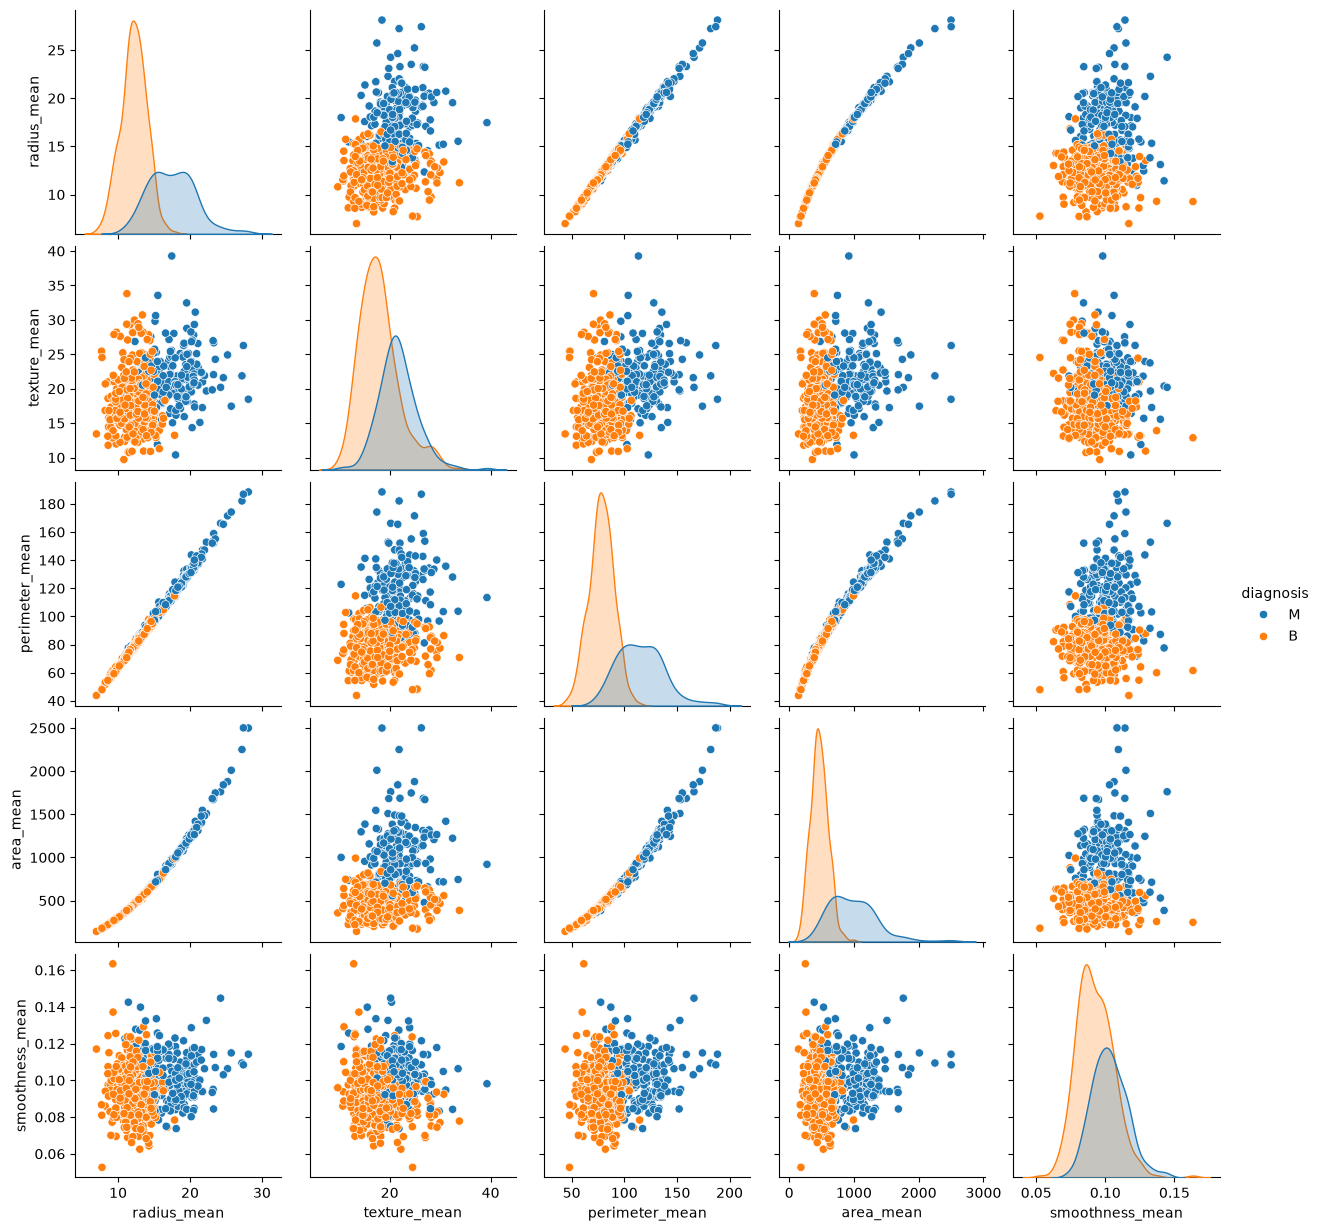

In [15]:
sns.pairplot(dados,vars=["radius_mean","texture_mean","perimeter_mean","area_mean","smoothness_mean"],hue="diagnosis")

# Analisando a correlação 🔎

Antes de dividir os dados em variáveis preditoras (X) e rótulo (y), vamos entender como as variáveis se relacionam entre si. Isso ajuda a identificar *features* redundantes e reforça por que uma técnica de redução de dimensionalidade, como o PCA que aplicaremos mais adiante, faz sentido para este dataset.

In [16]:
# Criando dataframe somente com nossas variáveis numericas
dados_numerico = dados.select_dtypes([np.number])
# Calcula a matriz de correlação
correlation_matrix = dados_numerico.corr()
correlation_matrix

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
radius_mean,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,0.679090,-0.097317,0.674172,0.735864,-0.222600,0.206000,0.194204,0.376169,-0.104321,-0.042641,0.969539,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066
texture_mean,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,0.275869,0.386358,0.281673,0.259845,0.006614,0.191975,0.143293,0.163851,0.009127,0.054458,0.352573,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205
perimeter_mean,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,0.691765,-0.086761,0.693135,0.744983,-0.202694,0.250744,0.228082,0.407217,-0.081629,-0.005523,0.969476,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019
area_mean,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,0.732562,-0.066280,0.726628,0.800086,-0.166777,0.212583,0.207660,0.372320,-0.072497,-0.019887,0.962746,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738
smoothness_mean,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,0.301467,0.068406,0.296092,0.246552,0.332375,0.318943,0.248396,0.380676,0.200774,0.283607,0.213120,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316
compactness_mean,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,0.497473,0.046205,0.548905,0.455653,0.135299,0.738722,0.570517,0.642262,0.229977,0.507318,0.535315,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382
concavity_mean,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,0.631925,0.076218,0.660391,0.617427,0.098564,0.670279,0.691270,0.683260,0.178009,0.449301,0.688236,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930
concave points_mean,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,0.698050,0.021480,0.710650,0.690299,0.027653,0.490424,0.439167,0.615634,0.095351,0.257584,0.830318,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661
symmetry_mean,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,0.303379,0.128053,0.313893,0.223970,0.187321,0.421659,0.342627,0.393298,0.449137,0.331786,0.185728,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413
fractal_dimension_mean,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,0.000111,0.164174,0.039830,-0.090170,0.401964,0.559837,0.446630,0.341198,0.345007,0.688132,-0.253691,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297


A matriz acima confirma uma forte multicolinearidade entre variáveis relacionadas ao tamanho do tumor: `radius_mean` e `perimeter_mean` têm correlação de **1,00**, e `area_mean` está correlacionada em **0,99** com `radius_mean`. Isso é esperado, já que raio, perímetro e área são medidas geometricamente dependentes do mesmo tumor — o mesmo padrão se repete entre as variáveis `_worst` (ex: `radius_worst` vs `perimeter_worst` = 0,99).

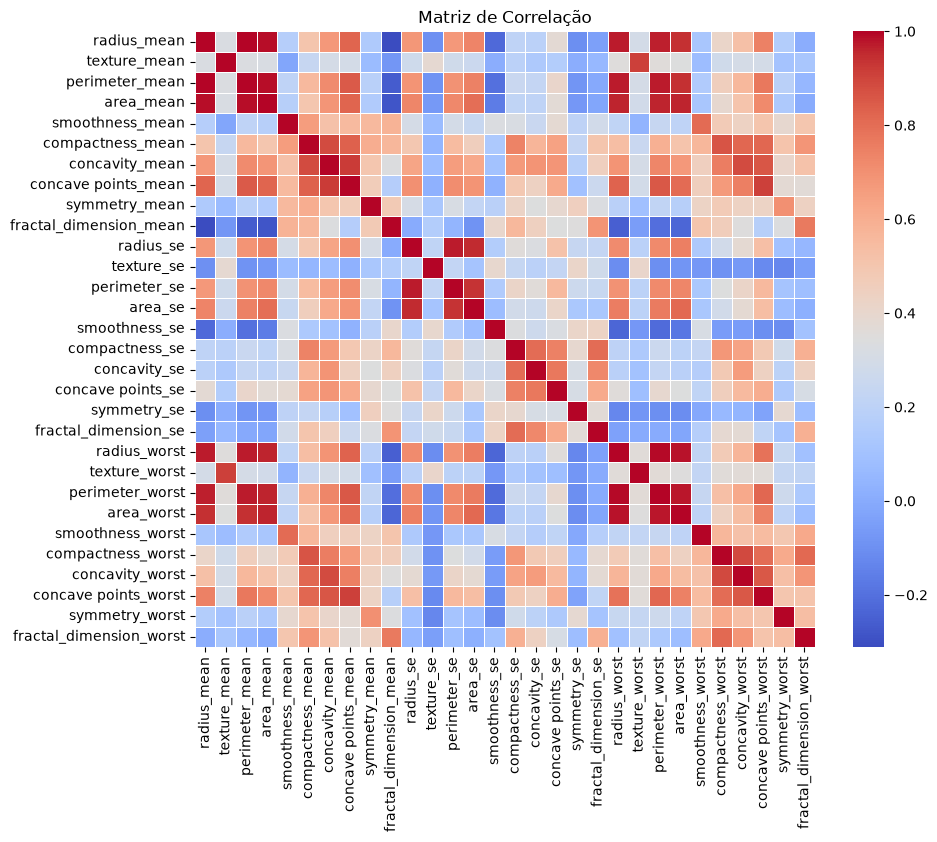

In [17]:
# Visualização da matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlação')
plt.show()

O mapa de calor deixa ainda mais visível esses blocos de alta correlação (tons mais próximos do vermelho), principalmente entre as variáveis `_mean`, `_se` e `_worst` ligadas ao tamanho do tumor. Essa redundância é justamente o tipo de problema que o PCA ajuda a resolver: em vez de manter diversas colunas quase idênticas, o método combina essa informação em componentes principais não correlacionados entre si, preservando a maior parte da variância original — como veremos na próxima seção.

In [18]:
features = ["radius_mean","texture_mean","perimeter_mean","area_mean","smoothness_mean","compactness_mean","concavity_mean","concave points_mean","symmetry_mean","fractal_dimension_mean","radius_se","texture_se","perimeter_se","area_se","smoothness_se","compactness_se","concavity_se","concave points_se","symmetry_se","fractal_dimension_se","radius_worst","texture_worst","perimeter_worst","area_worst","smoothness_worst","compactness_worst","concavity_worst","concave points_worst","symmetry_worst","fractal_dimension_worst"]
# Dividindo os dados em conjuntos de treinamento e teste

x = dados[features].values # Recurso (variável independente)

y = dados["diagnosis"].values # Rótulo (variável dependente)

Transformando o nosso **Y**, a coluna da string `diagnosis`, em uma coluna numérica binária de 0 e 1 com a função `LabelEnconder`

In [19]:
# Importando o LabelEncoder
from sklearn.preprocessing import LabelEncoder

label_enconder = LabelEncoder() # Aplica o LabelEncoder na coluna de diagnóstico (M=1, B=0)
y_encoder = label_enconder.fit_transform(dados['diagnosis'])

In [20]:
y_encoder

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

### Dividindo em treino e teste antes de qualquer ajuste estatístico

Para evitar vazamento de dados (*data leakage*), precisamos separar treino e teste **antes** de calcular qualquer estatística sobre os dados — como a média/desvio-padrão usados na padronização ou os componentes do PCA. Se ajustássemos essas etapas no conjunto completo, o modelo teria acesso indireto a informações do conjunto de teste, inflando artificialmente as métricas de avaliação mais adiante.

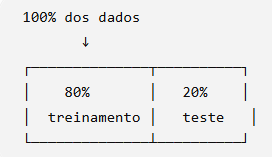

In [21]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y_encoder, test_size=0.2, random_state=42, stratify=y_encoder)

### **A Necessidade de Padronização das Variáveis**

A padronização dos dados é uma etapa fundamental no pré-processamento, especialmente ao trabalhar com a Análise de Componentes Principais (PCA) e modelos de aprendizado de máquina.

**Por que padronizar?**
* **Sensibilidade à Escala:** O PCA e algoritmos baseados em distância (como KNN e SVM) ou otimização por gradiente (como Regressão Logística) são altamente sensíveis à magnitude das variáveis. Variáveis com grandes amplitudes numéricas dominam desproporcionalmente o cálculo de variância e as métricas de distância, fazendo com que o modelo ignore atributos de menor escala.
* **Diferença de Granularidade no Dataset:** No conjunto de dados analisado, enquanto a variável `area_mean` atinge valores da ordem de $2.500$, a variável `concavity_mean` possui valores decimais concentrados entre $0,0$ e $0,42$. Sem o ajuste de escala, a área teria um peso artificialmente muito maior do que a concavidade na construção dos componentes e no treinamento do classificador. Optou-se pelo `StandardScaler` (em vez do `MinMaxScaler`) por ser mais robusto à presença de *outliers* identificados nas análises visuais (`boxenplot`). O `MinMaxScaler` encolheria a maior parte dos dados para um intervalo muito estreito caso existissem valores discrepantes extremos, enquanto o `StandardScaler` preserva a distribuição dos dados de forma mais estável.
  *   **MinMaxScaler (Escala 0 a 1):** Espreme todos os dados para caberem obrigatoriamente entre $0$ e $1$. O problema: se houver um valor extremo (um outlier, como um ponto fora da curva), ele vai puxar esse limite e esmagar quase todos os outros dados em um espaço minúsculo bem perto de zero.
  *   **StandardScaler (Padronização):** Centraliza os dados no meio (zero) e mede a distância em "passos" normais. Se surgir um valor fora da curva, ele simplesmente fica como um ponto mais distante, sem esmagar ou estragar a distribuição dos dados normais. Por isso ele é mais seguro e estável quando existem outliers.

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# treina e transforma meu dados do treino
x_train_padronizado = scaler.fit_transform(x_train)
# transforma meu dados teste
x_test_padronizado = scaler.transform(x_test)

x_padronizado = pd.DataFrame(data=x_train_padronizado, columns = features)
display(x_padronizado.head())

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0.518559,0.891826,0.424632,0.383925,-0.974744,-0.689772,-0.688586,-0.398175,-1.039155,-0.825056,-0.109318,-0.055976,-0.210096,-0.015913,-1.005184,-0.911942,-0.662816,-0.652561,-0.701889,-0.275394,0.579798,1.313242,0.466908,0.445983,-0.596155,-0.634722,-0.610227,-0.235744,0.054566,0.021837
1,-0.516364,-1.639710,-0.541349,-0.542961,0.476219,-0.631834,-0.604281,-0.303075,0.521543,-0.454523,-0.604378,-1.001046,-0.585429,-0.493454,0.403212,-0.768173,-0.479187,0.114508,-0.142951,-0.577398,-0.582459,-1.690291,-0.611934,-0.587014,0.273582,-0.814844,-0.712666,-0.323208,-0.137576,-0.904402
2,-0.368118,0.455515,-0.388250,-0.402970,-1.432979,-0.383927,-0.342175,-0.765459,-0.850857,-0.226171,0.303980,1.051501,-0.169545,-0.000809,-0.310104,1.106330,0.622585,0.273685,0.754483,1.508105,-0.398622,0.181977,-0.475431,-0.420778,-1.622785,-0.391399,-0.431313,-0.890825,-0.675893,-0.144016
3,0.205285,0.726168,0.400330,0.070612,0.243253,2.203585,2.256094,1.213233,0.818474,0.899791,-0.545730,-0.621677,0.261427,-0.353585,0.024460,2.090728,1.490561,1.695127,-0.654909,0.767548,-0.000309,0.274191,0.513776,-0.099482,0.418538,2.865970,2.958619,1.977064,-0.075646,1.728848
4,1.243005,0.194195,1.210377,1.206652,-0.111442,0.051348,0.732962,0.713767,-0.427187,-0.822184,1.523863,1.143941,1.282748,1.081313,1.351845,0.107731,0.592927,1.180988,0.301550,0.171527,1.012835,0.223144,0.938517,0.880910,0.073201,-0.277006,0.327775,0.501859,-0.909322,-0.546249


# PCA 🔍

Agora vamos importar o PCA usando o `sklearn` e projetar nossos dados — que possuem 30 dimensões — em um número menor de dimensões (também chamadas de componentes principais). Antes de aplicarmos o método, vamos descobrir qual é o número ideal de componentes para representar bem os dados.

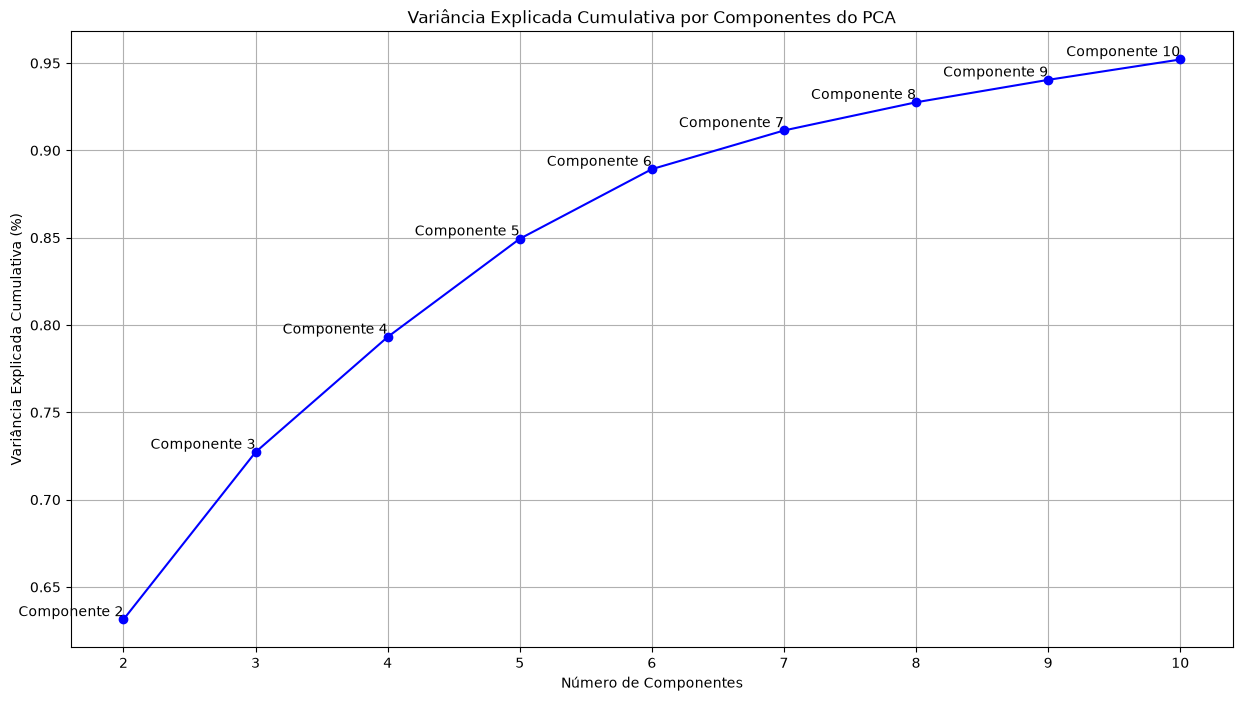

In [23]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Crie uma lista para armazenar os resultados
results = []
# Dados de exemplo (substitua pelo seu conjunto de dados X)
q = x_train_padronizado
# Faça um loop de 2 a 10 componentes
for n in range(2, 11):
    # Crie o objeto PCA
    pca = PCA(n_components=n)
    # Ajuste o PCA aos seus dados
    pca.fit(q)
    # Calcule a variância explicada cumulativa e adicione aos resultados
    explained_variance = np.sum(pca.explained_variance_ratio_)
    results.append(explained_variance)

# Crie o gráfico
plt.figure(figsize=(15, 8))
plt.plot(range(2, 11), results, marker='o', linestyle='-', color='b')
plt.xlabel('Número de Componentes')
plt.ylabel('Variância Explicada Cumulativa (%)')
plt.title('Variância Explicada Cumulativa por Componentes do PCA')
plt.grid(True)

# Adicione rótulos aos pontos de dados
for i, (n_components, explained_var) in enumerate(zip(range(2, 11), results)):
    plt.text(n_components, explained_var, f'Componente {n_components}', ha='right', va='bottom')

In [24]:
# Importando PCA da biblioteca sklearn
from sklearn.decomposition import PCA

# Instanciando o PCA com a quantidade de componentes que desejamos obter
pca = PCA(n_components=10)

# Ajusta o PCA SÓ no treino, e projeta treino e teste com o mesmo ajuste
x_train_pca = pca.fit_transform(x_train_padronizado)
x_test_pca = pca.transform(x_test_padronizado)

In [25]:
# Criando os DataFrames das componentes (treino e teste separados)
dados_pca_train = pd.DataFrame(data=x_train_pca, columns=['PC1', 'PC2',"PC3","PC4","PC5","PC6","PC7","PC8","PC9","PC10"])
dados_pca_train['diagnosis'] = y_train

dados_pca_test = pd.DataFrame(data=x_test_pca, columns=['PC1', 'PC2',"PC3","PC4","PC5","PC6","PC7","PC8","PC9","PC10"])
dados_pca_test['diagnosis'] = y_test


In [26]:
dados_pca_train.tail()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,diagnosis
450,-3.730069,-1.364877,1.713709,0.555606,-0.051602,0.287981,-0.498935,2.001406,-0.770976,-0.826061,0
451,-1.894651,0.942551,0.074451,0.458228,1.348708,0.091180,-0.641665,-0.730841,0.193618,0.422775,0
452,-3.180442,-1.992055,0.009280,1.811156,0.312800,-0.496644,-0.278725,-0.211116,0.642944,0.346642,0
453,-0.568062,-0.906734,-0.314257,0.535105,-1.395945,-0.070732,0.278596,0.088039,-0.087852,-0.487177,0
454,3.171861,-1.573469,1.196476,0.677494,0.917171,-1.134662,-0.215635,1.287941,0.629071,-0.968782,1


#Métrica estatística sobre qualidade da minha redução de componentes
"A técnica do PCA parece muito interessante! No entanto, como posso ter certeza de que o PCA não está omitindo informações essenciais para o meu modelo?"

Para esclarecer essa preocupação, utilizamos uma técnica chamada "Razão de Variância Explicada" (Explained Variance Ratio). Essa métrica estatística quantifica o quanto de variação em um conjunto de dados pode ser atribuído a cada um dos componentes principais (que são criados pelo PCA) em relação à média. Isso é fundamental, pois nos permite classificar os componentes por ordem de importância e concentrar nossa atenção nos mais significativos ao interpretar os resultados da análise.

A variância explicada é uma ferramenta que ajuda a escolher quantas dimensões devem ser mantidas em um conjunto de dados reduzido. Além disso, ela também pode ser usada para avaliar a qualidade de um modelo de aprendizado de máquina. Em geral, um modelo com uma alta variância explicada tende a ter um bom poder de previsão, enquanto um modelo com uma baixa variância explicada pode não ser tão preciso. No entanto, é importante lembrar que a interpretação depende da pergunta que estamos tentando responder com os dados.

Vamos olhar agora como ficou a variabilidade de cada componente principal, ou seja, o quanto cada coluna gerada a partir do PCA estão próximos/distantes da média dos nossos dados.

In [27]:
# Exibir a proporção de variância explicada
print('Variance of each component:', pca.explained_variance_ratio_)
print('\n Total Variance Explained:', round(sum(list(pca.explained_variance_ratio_))*100, 2))

Variance of each component: [0.44593522 0.18545255 0.09584641 0.06593768 0.05622286 0.03988488
 0.02214493 0.01614006 0.01284789 0.01165661]

 Total Variance Explained: 95.21


Se você tem um PC1 de 0.44593522, isso significa que o primeiro componente principal da sua análise é responsável por aproximadamente 44.59% da variância nos seus dados. Em outras palavras, esse único componente principal captura cerca de 44.59% da informação ou "estrutura" dos seus dados em termos de variância. Os restantes da variância são capturados pelos outros componentes principais (PC2, PC3, etc.).

o **PCA** (Análise de Componentes Principais) foi incluído na etapa de **pré-processamento** como uma tentativa de reduzir a dimensionalidade dos dados e eliminar a multicolinearidade entre atributos altamente correlacionados (identificada na análise de correlação). A motivação teórica para isso é a chamada **maldição da dimensionalidade**: algoritmos baseados em distância, como o KNN, tendem a perder desempenho à medida que o número de atributos cresce, porque a noção de "proximidade" entre pontos fica menos confiável em espaços muito dimensionais.

**Ainda estamos avaliando, porém, se essa técnica é de fato essencial para este projeto.** Até o momento, reduzir de 30 para 10 componentes não trouxe um ganho expressivo de desempenho, e teve um custo real: os componentes principais deixam de carregar os nomes das variáveis originais (`radius_mean`, `texture_mean` etc.), o que prejudica a interpretabilidade do modelo — algo relevante em um contexto de diagnóstico médico. Essa discussão sobre manter ou não o PCA no pipeline final será aprofundada nas próximas seções, comparando o desempenho dos classificadores com e sem essa etapa.

Vamos testar o **KNN** e os demais algoritmos (**Decision Tree**, **Random Forest**, **Regressão Logística** e **SVM**).

In [28]:
from sklearn.neighbors import KNeighborsClassifier

Vamos testar o algoritmo e validar os resultados!

 Testa o algoritmo **KNN** sem padronização e sem PCA

In [29]:
model = KNeighborsClassifier(n_neighbors=3)

# Treinar o modelo
model.fit(x_train, y_train)

# Fazer previsões no conjunto de teste
y_pred = model.predict(x_test)

In [30]:
from sklearn.metrics import accuracy_score

# Avaliar a precisão do modelo
accuracy = accuracy_score(y_test, y_pred)
print(f'Acurácia: {accuracy:.2f}')

Acurácia: 0.92


Testando com a padronização sem PCA

In [31]:
model_padronizado = KNeighborsClassifier(n_neighbors=3)

# Treinar o modelo
model_padronizado.fit(x_train_padronizado, y_train)

# Fazer previsões no conjunto de teste
y_pred_padronizado = model_padronizado.predict(x_test_padronizado)

accuracy_padronizada = accuracy_score(y_test, y_pred_padronizado)
print(f'Acurácia: {accuracy_padronizada:.2f}')

Acurácia: 0.94


Testando com PCA

In [32]:
model_pca = KNeighborsClassifier(n_neighbors=3)

# Treinar o modelo
model_pca.fit(x_train_pca, y_train)

# Fazer previsões no conjunto de teste
y_pred_pca = model_pca.predict(x_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
print(f'Acurácia: {accuracy_pca:.2f}')

Acurácia: 0.95


Será que `n_neighbors=3` é o nosso modelo melhor não existe uma forma de descobrir?

Text(0, 0.5, 'Mean Error')

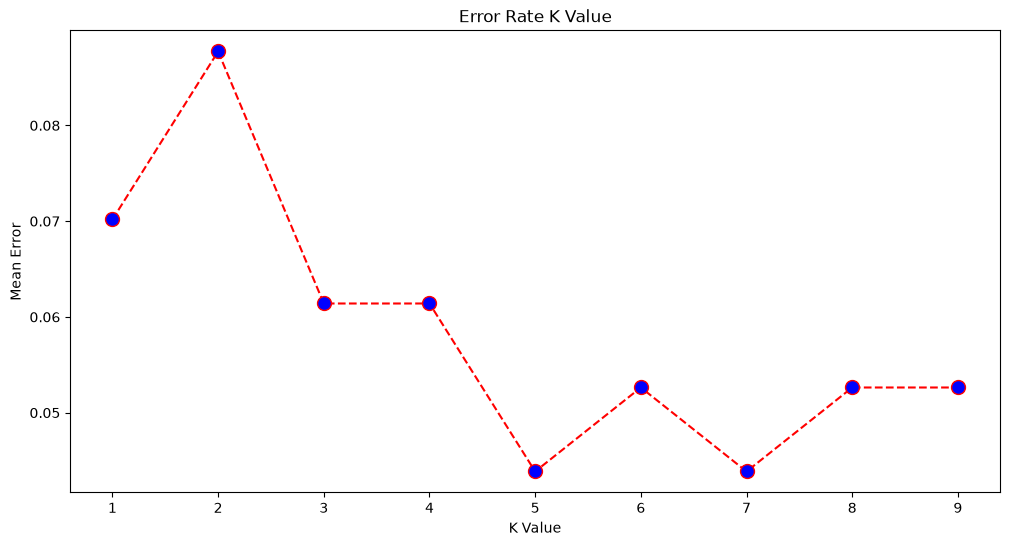

In [33]:
# Armazena o error para cada quantidade de k
error = []

# Calculating error for K values between 1 and 10
for i in range(1, 10):
    knn = KNeighborsClassifier(n_neighbors=i)
    #treinando o algoritmo para encontrar o erro
    knn.fit(x_train_padronizado, y_train)
    #armazenando as previsões
    pred_i = knn.predict(x_test_padronizado)
    #armazenando o valor do erro médio na lista de erros
    error.append(np.mean(pred_i != y_test))

# Plota o gráfico
plt.figure(figsize=(12, 6))
plt.plot(range(1, 10), error, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=10)
plt.title('Error Rate K Value')
plt.xlabel('K Value')
plt.ylabel('Mean Error')

Testando o algoritmo **SVM:**

 Testa o algoritmo **SVM** sem padronização e sem PCA

In [34]:
from sklearn.svm import LinearSVC

# Instanciando o modelo
model_svm = LinearSVC(C=1, random_state=42)

# Treinamento e predição
model_svm.fit(x_train, y_train)
y_predito_svm = model_svm.predict(x_test)

# Avaliação
print(accuracy_score(y_test, y_predito_svm))

0.9298245614035088


Testando com a padronização sem PCA

In [35]:
from sklearn.svm import LinearSVC

# Instanciando o modelo
model_svm_padronizado = LinearSVC(C=1, random_state=42)

# Treinamento e predição
model_svm_padronizado.fit(x_train_padronizado, y_train)
y_predito_padronização_svm = model_svm_padronizado.predict(x_test_padronizado)

# Avaliação
print(accuracy_score(y_test, y_predito_padronização_svm))

0.9649122807017544


Testando com PCA

In [36]:
from sklearn.svm import LinearSVC

# Instanciando o modelo
model_svm_pca = LinearSVC(C=1, random_state=42)

# Treinamento e predição
model_svm_pca.fit(x_train_pca, y_train)
y_predito_pca_svm = model_svm_pca.predict(x_test_pca)

# Avaliação
print(accuracy_score(y_test, y_predito_pca_svm))

0.9649122807017544


## **Analisando resultados**

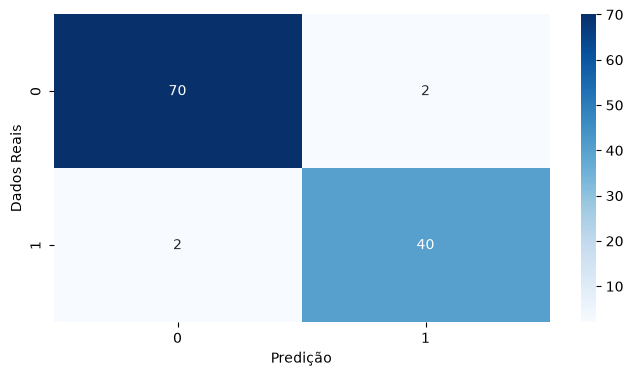

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_confusao = confusion_matrix(y_test, y_predito_pca_svm)
plt.figure(figsize = (8, 4))
sns.heatmap(matriz_confusao, annot = True, fmt="d",cmap = "Blues")
plt.xlabel("Predição");
plt.ylabel("Dados Reais");

In [38]:
from sklearn.metrics import recall_score, precision_score, f1_score

# Consolidando accuracy, recall, precision e F1 de todas as combinações já testadas
resumo_resultados = pd.DataFrame([

    # KNN
    {'Modelo': 'KNN sem padronização',  'Accuracy': accuracy_score(y_test, y_pred),
     'Recall': recall_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred),
     'F1-score': f1_score(y_test, y_pred)},
    {'Modelo': 'KNN padronizado', 'Accuracy': accuracy_score(y_test, y_pred_padronizado),
     'Recall': recall_score(y_test, y_pred_padronizado), 'Precision': precision_score(y_test, y_pred_padronizado),
     'F1-score': f1_score(y_test, y_pred_padronizado)},
    {'Modelo': 'KNN com PCA', 'Accuracy': accuracy_score(y_test, y_pred_pca),
     'Recall': recall_score(y_test, y_pred_pca), 'Precision': precision_score(y_test, y_pred_pca),
     'F1-score': f1_score(y_test, y_pred_pca)},

    # SVM
    {'Modelo': 'SVM sem padronização', 'Accuracy': accuracy_score(y_test, y_predito_svm),
     'Recall': recall_score(y_test, y_predito_svm), 'Precision': precision_score(y_test, y_predito_svm),
     'F1-score': f1_score(y_test, y_predito_svm)},
    {'Modelo': 'SVM padronizado', 'Accuracy': accuracy_score(y_test, y_predito_padronização_svm),
     'Recall': recall_score(y_test, y_predito_padronização_svm), 'Precision': precision_score(y_test, y_predito_padronização_svm),
     'F1-score': f1_score(y_test, y_predito_padronização_svm)},
    {'Modelo': 'SVM com PCA', 'Accuracy': accuracy_score(y_test, y_predito_pca_svm),
     'Recall': recall_score(y_test, y_predito_pca_svm), 'Precision': precision_score(y_test, y_predito_pca_svm),
     'F1-score': f1_score(y_test, y_predito_pca_svm)},
])

display(resumo_resultados)


,Modelo,Accuracy,Recall,Precision,F1-score
0,KNN sem padronização,0.921053,0.785714,1.000000,0.880000
1,KNN padronizado,0.938596,0.857143,0.972973,0.911392
2,KNN com PCA,0.947368,0.880952,0.973684,0.925000
3,SVM sem padronização,0.929825,0.857143,0.947368,0.900000
4,SVM padronizado,0.964912,0.928571,0.975000,0.951220
5,SVM com PCA,0.964912,0.952381,0.952381,0.952381


### 1. Avaliação do modelo com os dados de teste

Até aqui, avaliamos cada combinação (KNN e SVM, com e sem padronização/PCA) usando `accuracy_score` no `x_test`/`y_test` — o conjunto que ficou intocado desde o início, garantindo que a avaliação reflete dados nunca vistos pelo modelo. A tabela acima consolida, além da acurácia, o **recall** e o **F1-score** de todas as 6 combinações testadas.

**Por que não basta olhar só a acurácia?** No nosso dataset, 62,7% dos casos são Benignos e 37,3% Malignos — um desbalanceamento leve, mas suficiente para que a acurácia sozinha esconda erros importantes. É exatamente isso que aparece nos números: o **KNN sem padronização** tem accuracy de 0,92, mas recall de apenas **0,79** — ele deixa passar cerca de 1 em cada 5 tumores malignos do conjunto de teste.
**A métrica mais importante para este problema é o recall da classe Maligna.** Em diagnóstico médico, um falso negativo (dizer que o tumor é benigno quando na verdade é maligno) é muito mais grave que um falso positivo — o primeiro pode atrasar um tratamento necessário, o segundo, na pior das hipóteses, leva a exames adicionais. Por isso, entre acurácia, recall e F1, priorizamos o **recall**, e usamos o **F1-score** como métrica de equilíbrio para não escolher um modelo que maximiza recall sacrificando precisão de forma exagerada (gerando excesso de falsos positivos e exames desnecessários).

### 2. Discussão crítica: esse modelo pode ser usado na prática?

O melhor resultado obtido até aqui foi o **SVM com PCA**, com recall de **0,952** — ou seja, de 42 pacientes com tumor maligno no conjunto de teste, o modelo identificou corretamente 40 e deixou passar 2. O desempenho é bom, mas **não seria responsável usar esse modelo sozinho como diagnóstico final**: mesmo esses 2 casos não identificados já seriam inaceitáveis se a decisão do modelo fosse a palavra final, sem revisão humana. Em todos esses usos, **o médico continua com a palavra final no diagnóstico** — o modelo é um segundo par de "olhos" estatísticos,ou seja um copiloto, não uma autoridade substituta. Isso é ainda mais importante considerando que nosso dataset tem apenas 569 amostras, de um único conjunto de exames: um modelo treinado nesses dados pode não generalizar bem a populações.

# **Validação Cruzada**

Até aqui, avaliamos cada modelo com um único `train_test_split`: separamos 80% para treino e 20% para teste, e olhamos a acurácia daquele teste específico. Isso levanta uma pergunta: **será que existe um jeito mais rápido — e mais confiável — de validar meu modelo?**

A resposta é sim, e é exatamente pra isso que serve a **validação cruzada** (*cross-validation*). Ela resolve dois problemas:

1. **Velocidade/praticidade:** em vez de eu escrever manualmente um `for`, gerar vários `train_test_split` com seeds diferentes, treinar o modelo em cada um e depois tirar a média das acurácias na mão, o `cross_val_score` do `sklearn` faz tudo isso em uma única chamada de função.
2. **Confiabilidade:** um único split pode, por sorte ou azar, cair num conjunto de teste "fácil" ou "difícil" para o modelo — e eu nunca saberia se o resultado que vi foi sorte ou desempenho real. A validação cruzada treina e avalia o modelo várias vezes, em pedaços diferentes dos dados, e no final calcula a média (e o desvio-padrão) dessas avaliações — um retrato bem mais robusto de como o modelo se comporta.

**A diferença central, então, é essa:** o `train_test_split` dá **um** número de desempenho baseado em **uma** divisão dos dados; a validação cruzada dá a **média de vários** números, cada um vindo de uma divisão diferente — o que reduz a chance de tirar uma conclusão errada por causa de um split "de sorte".

A técnica mais usada pra isso é o **K-Fold**: os dados são divididos em `K` pedaços (chamados *folds*) de tamanho parecido. Usaremos `K = 5` — ou seja, 5 rodadas de treino/validação, revezando qual pedaço é usado para validar em cada rodada, como mostra o esquema abaixo.

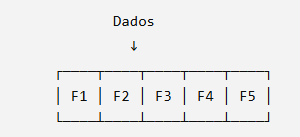

####Rodada 1 → valida F1 | treina F2 F3 F4 F5
####Rodada 2 → valida F2 | treina F1 F3 F4 F5
####Rodada 3 → valida F3 | treina F1 F2 F4 F5
####Rodada 4 → valida F4 | treina F1 F2 F3 F5
####Rodada 5 → valida F5 | treina F1 F2 F3 F4

### Validação cruzada — todos os algoritmos

In [39]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metricas = {
    "accuracy": "accuracy",
    "recall": "recall",
    "f1": "f1",
}

modelos = {
    'KNN': KNeighborsClassifier(n_neighbors=3),
    'SVM': LinearSVC(C=1, random_state=42),
    'Regressão Logística': LogisticRegression(random_state=42),
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
}

resultados = []

for nome, modelo in modelos.items():
    pipeline_sem_pca = Pipeline([
        ("padronizacao", StandardScaler()),
        ("algoritmo", modelo)
    ])
    r_sem_pca = cross_validate(pipeline_sem_pca, x_train, y_train, cv=cv, scoring=metricas)

    pipeline_com_pca = Pipeline([
        ("padronizacao", StandardScaler()),
        ("pca", PCA(n_components=10)),
        ("algoritmo", modelo)
    ])
    r_com_pca = cross_validate(pipeline_com_pca, x_train, y_train, cv=cv, scoring=metricas)

    resultados.append({
        "Algoritmo": nome,
        "Acurácia (Sem PCA)": r_sem_pca["test_accuracy"].mean(),
        "Recall (Sem PCA)": r_sem_pca["test_recall"].mean(),
        "F1 (Sem PCA)": r_sem_pca["test_f1"].mean(),
        "Acurácia (Com PCA)": r_com_pca["test_accuracy"].mean(),
        "Recall (Com PCA)": r_com_pca["test_recall"].mean(),
        "F1 (Com PCA)": r_com_pca["test_f1"].mean(),
    })

resultados_df = pd.DataFrame(resultados)
display(resultados_df)


,Algoritmo,Acurácia (Sem PCA),Recall (Sem PCA),F1 (Sem PCA),Acurácia (Com PCA),Recall (Com PCA),F1 (Com PCA)
0,KNN,0.973626,0.935294,0.963263,0.971429,0.935294,0.960451
1,SVM,0.969231,0.947059,0.958166,0.971429,0.947059,0.961182
2,Regressão Logística,0.973626,0.952941,0.964048,0.975824,0.952941,0.967068
3,Árvore de Decisão,0.923077,0.894118,0.896184,0.920879,0.888235,0.892560
4,Random Forest,0.964835,0.941176,0.951945,0.953846,0.923529,0.937113
